In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
from PIL import Image
from IPython.display import Markdown as MD
from numpy.linalg import norm
# Carregando dataset
with h5py.File('Data.hdf5') as f:
    A = f['A'][:]
    B = f['B'][:]
    G = f['G'][:]

F = np.array(Image.open('original.jpeg'))

def mdisp(arg): #Função auxiliar para realizar print com markdown
    display(MD(arg))

def vec(x:np.ndarray):
    x = np.atleast_2d(x)
    return x.reshape(np.prod(x.shape),1,order='F').squeeze()

c:\Users\bruno\.conda\envs\ykk2\lib\site-packages\numpy\_distributor_init.py:30: UserWarning: loaded more than 1 DLL from .libs:
c:\Users\bruno\.conda\envs\ykk2\lib\site-packages\numpy\.libs\libopenblas.FB5AE2TYXYH2IJRDKGDGQ3XBKLKTF43H.gfortran-win_amd64.dll
c:\Users\bruno\.conda\envs\ykk2\lib\site-packages\numpy\.libs\libopenblas64__v0.3.21-gcc_10_3_0.dll
  warnings.warn("loaded more than 1 DLL from .libs:"


## Uma breve revisão
O problema do
- Temos uma imagem $\mathbf{G}$
- 

In [28]:
Ua,Sa,Va = np.linalg.svd(A,)
Va = Va.T
Ub,Sb,Vb = np.linalg.svd(B,)
Vb = Vb.T

Gh = ((Ub.T @ G) @ Ua)
gh = vec(Gh)

Ss = np.outer(Sb,Sa)
S = np.kron(Sa,Sb)

def compute_solution(reg):
    global Vb,Gh,Ss,Va
    return Vb @ (Gh*Ss/(Ss**2 + reg**2)) @ Va.T

## Implementando o GCV

$$
V(\lambda) = 
\frac{
    \sum_i^{n^2} \left(\frac{ \hat{g}_i}{\sigma_i^2 + \lambda^2}\right)^2
}{
    \sum_i^{n^2} \left(\frac{i}{\sigma_i^2 + \lambda^2}\right)^2
}
$$

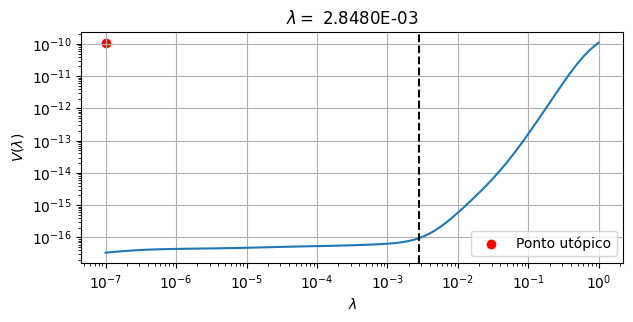

In [ ]:
# Computa V(lambda)
reg_grid = np.logspace(-7,0,num=100)
V = np.zeros(len(reg_grid))
for l_idx,lam in enumerate(reg_grid):
    V[l_idx] = ((gh/(S**2+lam**2))**2).sum()
    V[l_idx] /= (((np.arange(len(S))+1)/(S**2+lam**2))**2).sum()

# Determina Lambda ótimo como a distância máxima em relação a um ponto utopico
log_x,log_y = np.log(reg_grid), np.log(V)
utopia = np.array([log_x[0],log_y[-1]])
knee_idx = np.sqrt((log_x-utopia[0])**2 + (log_y-utopia[1])**2).argmax()

plt.figure(figsize=(7,3))
plt.plot(reg_grid,V)
plt.scatter(*np.exp(utopia),color='red',label='Ponto utópico')
plt.axvline(reg_grid[knee_idx],color='black',linestyle='dashed')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('$\\lambda$')
plt.ylabel('$V(\\lambda)$')
plt.title(f'$\\lambda =$ {reg_grid[knee_idx]:.4E}')
plt.grid()
plt.legend()
lam_opt = reg_grid[knee_idx]

In [ ]:

_reg_grid = np.logspace(-5,-1,num=30)

frames = []
for idx,reg in enumerate(_reg_grid):
    frame = {
        'lambda': reg,
        'image': compute_solution(reg)
    }
    frames.append(frame)
    pass

In [40]:
fig, axs = plt.subplots(1,2,figsize=(7, 4))
def update(frame_idx):
    for ax in axs:
        ax.clear()
    f = frames[frame_idx]
    axs[1].imshow(f['image'].T)
    axs[1].set_axis_off()

    axs[0].set_title(f"lambda = {f['lambda']:.2E}")
    axs[0].plot(reg_grid,V)
    axs[0].axvline(f['lambda'],color='blue',linestyle='dashed',label='$\\lambda$ atual')
    axs[0].axvline(lam_opt,color='black',linestyle='dashed',label='$\\lambda$ ótimo')
    axs[0].set_xscale('log')
    axs[0].set_yscale('log')
    axs[0].set_xlabel('$\\lambda$')
    axs[0].set_ylabel('$V(\\lambda)$')
    axs[0].grid()
    axs[0].legend()
    axs[0].set_xlim([reg_grid.min(),reg_grid.max()])

anim = FuncAnimation(fig, update, frames=len(frames), interval=(1/5)*1E3, repeat=True)
plt.close(fig)
HTML(anim.to_jshtml())

## Vamos comparar outros métodos